# WTI and Brent: futures vs spot

A simple look at how the **Yahoo front-month futures** (`CL=F`, `BZ=F`) compare with the **FRED/EIA spot prices** (`DCOILWTICO`, `DCOILBRENTEU`).

Why it matters: the futures series are *continuous front-month* series, so when a contract expires they jump to the next contract. That jump is a price spread, not a real return. Spot prices have no such jumps. Run `download_data.ipynb` first to create the CSV files in `Data/raw/`.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RAW = Path.cwd() / "Data" / "raw"
yahoo = pd.read_csv(RAW / "yahoo_daily.csv", index_col=0, parse_dates=True)
fred = pd.read_csv(RAW / "fred_daily.csv", index_col=0, parse_dates=True)

PAIRS = {"WTI": ("wti_fut", "wti_spot"), "Brent": ("brent_fut", "brent_spot")}
data = {}
for name, (fut, spot) in PAIRS.items():
    d = pd.concat([yahoo[fut].rename("futures"), fred[spot].rename("spot")], axis=1).dropna()
    d = d[(d > 0).all(axis=1)]                      # drop non-positive prices (WTI spot on 2020-04-20 was negative)
    d["fut_ret"] = np.log(d["futures"]).diff()      # daily log-returns
    d["spot_ret"] = np.log(d["spot"]).diff()
    d["ret_gap"] = d["fut_ret"] - d["spot_ret"]
    data[name] = d
    print(f"{name}: {len(d):,} days, {d.index.min().date()} -> {d.index.max().date()}")

WTI: 6,175 days, 2000-08-23 -> 2026-09-29
Brent: 4,724 days, 2007-07-30 -> 2026-09-29


## 1. Price levels

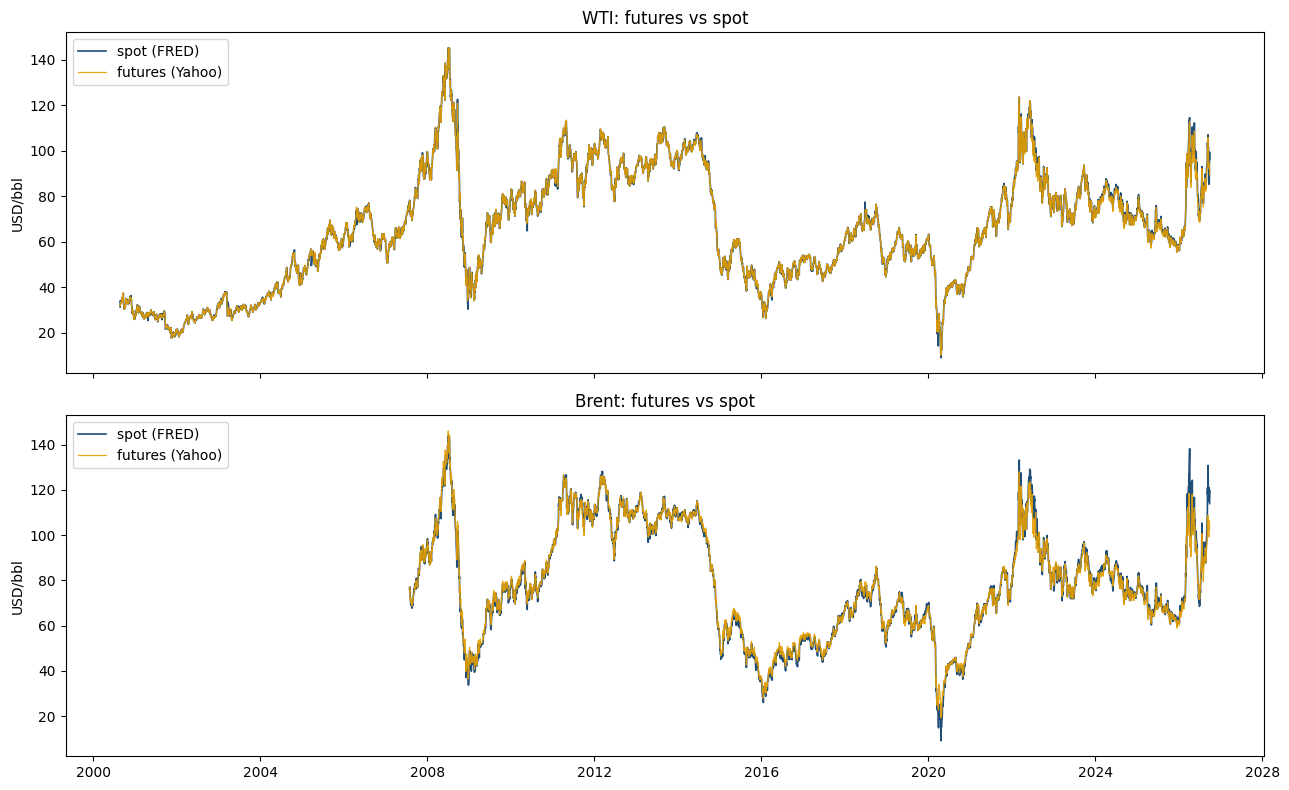

In [2]:
fig, ax = plt.subplots(2, 1, figsize=(13, 8), sharex=True)
for a, (name, d) in zip(ax, data.items()):
    a.plot(d.index, d["spot"], label="spot (FRED)", color="#1f4e79", lw=1.2)
    a.plot(d.index, d["futures"], label="futures (Yahoo)", color="#e69f00", lw=0.9, alpha=0.9)
    a.set_title(f"{name}: futures vs spot"); a.set_ylabel("USD/bbl"); a.legend(loc="upper left")
plt.tight_layout(); plt.show()

## 2. Price gap (futures minus spot)
In percent of the spot price. It is usually small, but spikes when the futures curve is steep (2008-09, 2020) and around contract rolls.

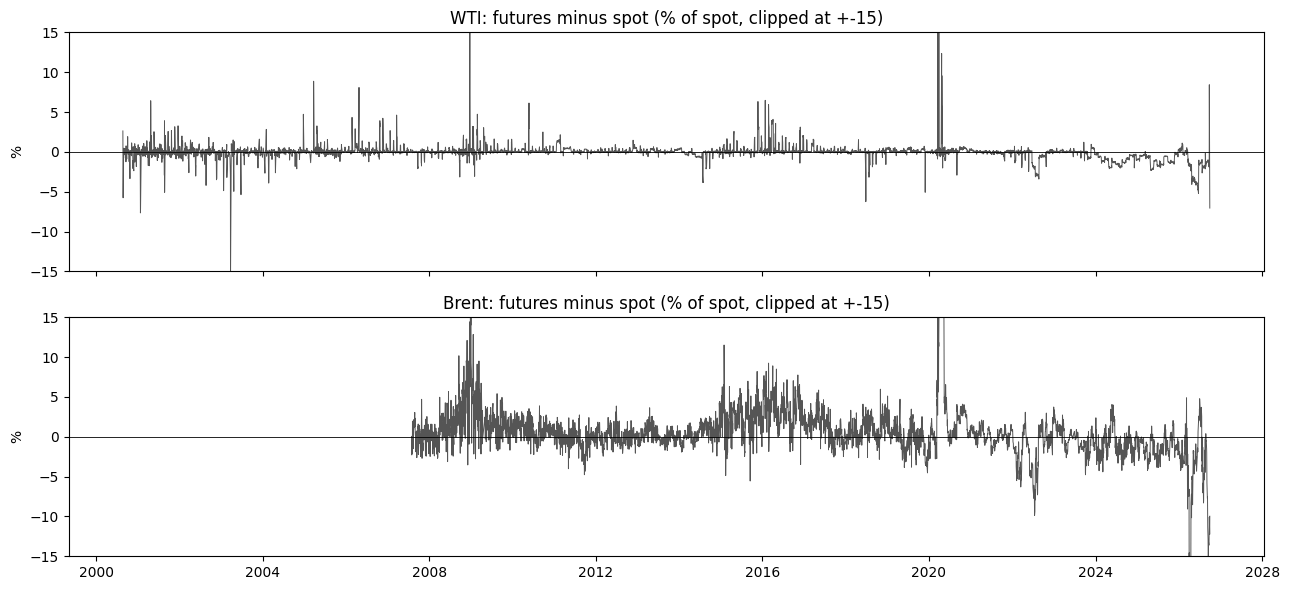

In [3]:
fig, ax = plt.subplots(2, 1, figsize=(13, 6), sharex=True)
for a, (name, d) in zip(ax, data.items()):
    gap = (d["futures"] / d["spot"] - 1) * 100
    a.plot(gap.index, gap, color="#555", lw=0.7); a.axhline(0, color="k", lw=0.6)
    a.set_ylim(-15, 15); a.set_title(f"{name}: futures minus spot (% of spot, clipped at +-15)"); a.set_ylabel("%")
plt.tight_layout(); plt.show()

## 2b. Absolute price difference in USD/bbl (futures minus spot)
The same gap in dollars instead of percent. Positive = futures above spot; negative = futures below spot. The lower panel for each pair zooms in on the last 90 days.

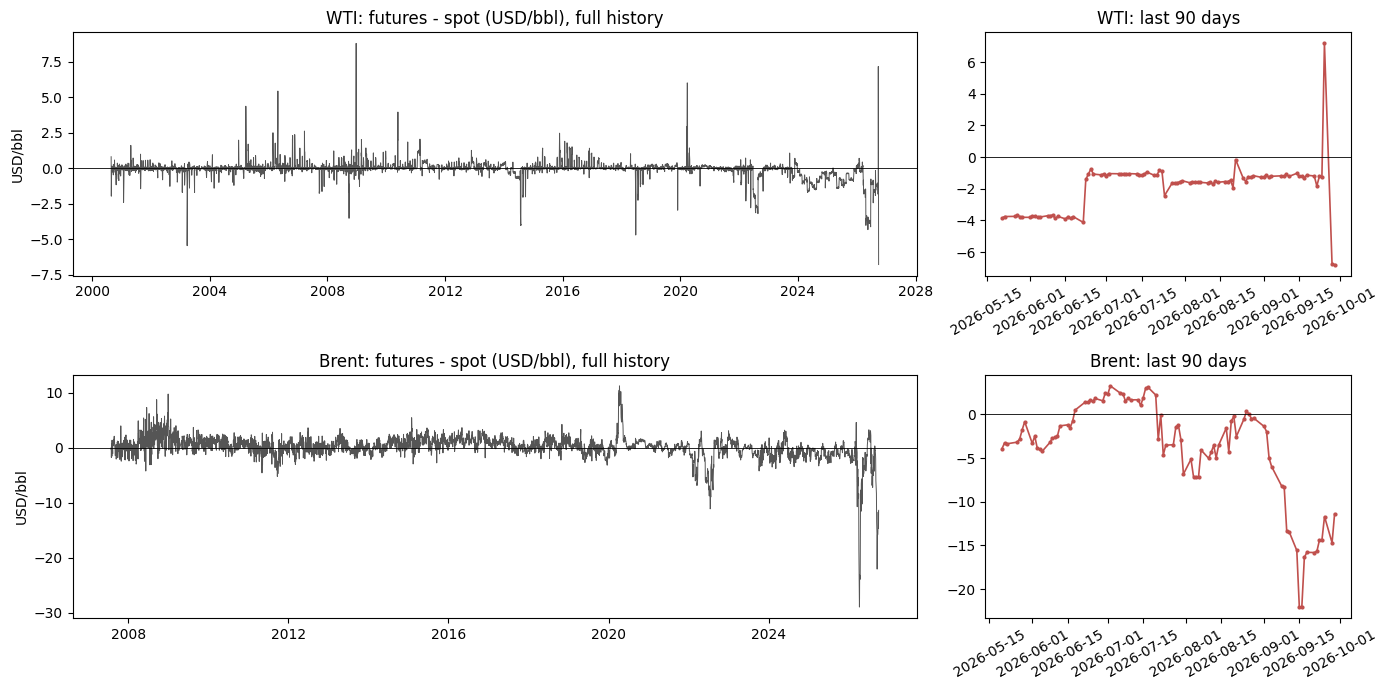

,mean,std,mean absolute difference,largest |difference|,"mean abs diff, last 90 days"
WTI,-0.09,0.65,0.29,8.81,2.06
Brent,0.08,2.25,1.32,28.94,4.79


In [6]:
fig, ax = plt.subplots(2, 2, figsize=(14, 7), gridspec_kw={"width_ratios": [3, 1.3]})
for row, (name, d) in zip(ax, data.items()):
    diff = d["futures"] - d["spot"]
    row[0].plot(diff.index, diff, color="#555", lw=0.7); row[0].axhline(0, color="k", lw=0.6)
    row[0].set_title(f"{name}: futures - spot (USD/bbl), full history"); row[0].set_ylabel("USD/bbl")
    z = diff.tail(90)
    row[1].plot(z.index, z, color="#c0504d", lw=1.2, marker="o", ms=2); row[1].axhline(0, color="k", lw=0.6)
    row[1].set_title(f"{name}: last 90 days"); row[1].tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.show()

summ = pd.DataFrame({name: {"mean": (d.futures - d.spot).mean(), "std": (d.futures - d.spot).std(),
                            "mean absolute difference": (d.futures - d.spot).abs().mean(),
                            "largest |difference|": (d.futures - d.spot).abs().max(),
                            "mean abs diff, last 90 days": (d.futures - d.spot).abs().tail(90).mean()} for name, d in data.items()}).T
display(summ.round(2))

## 3. Daily return charts
Daily log-returns of futures and spot, and the difference between them. Every spike in the bottom panel is a day when the two series disagree.

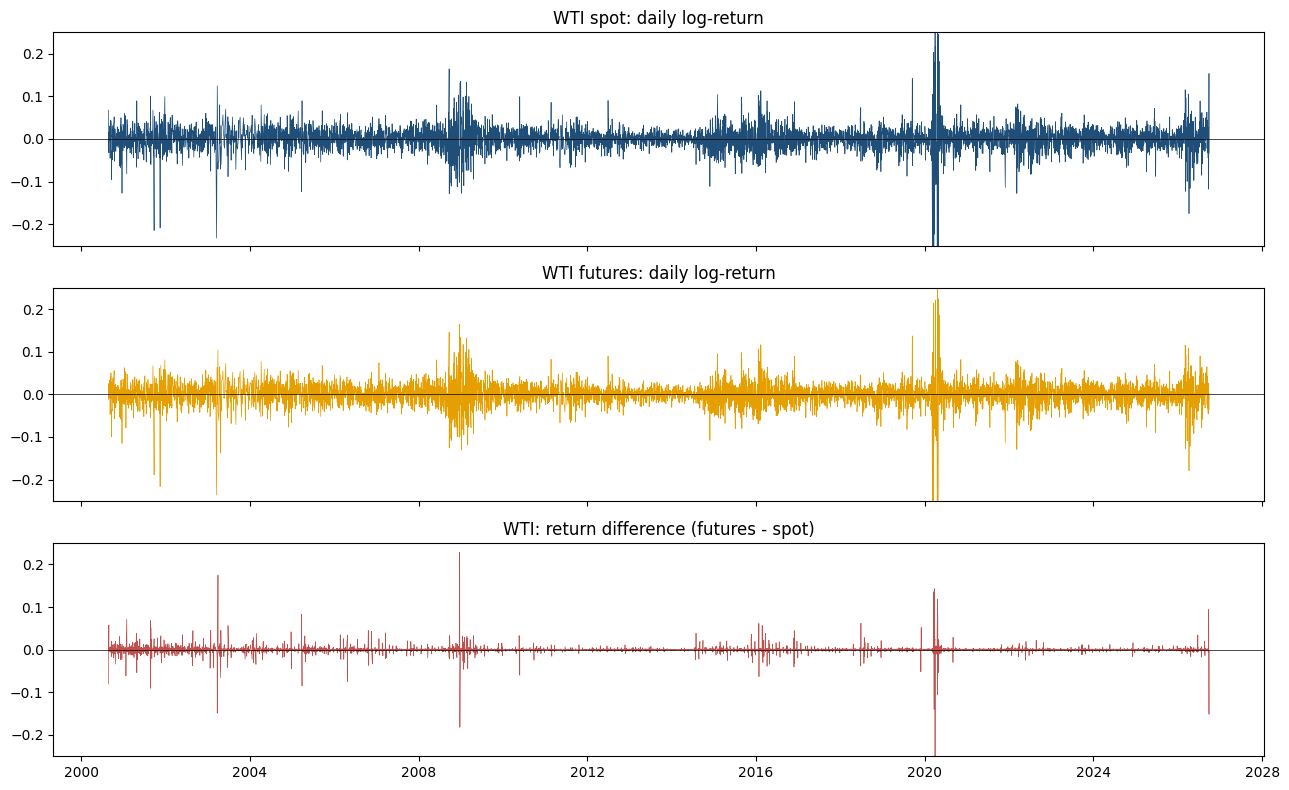

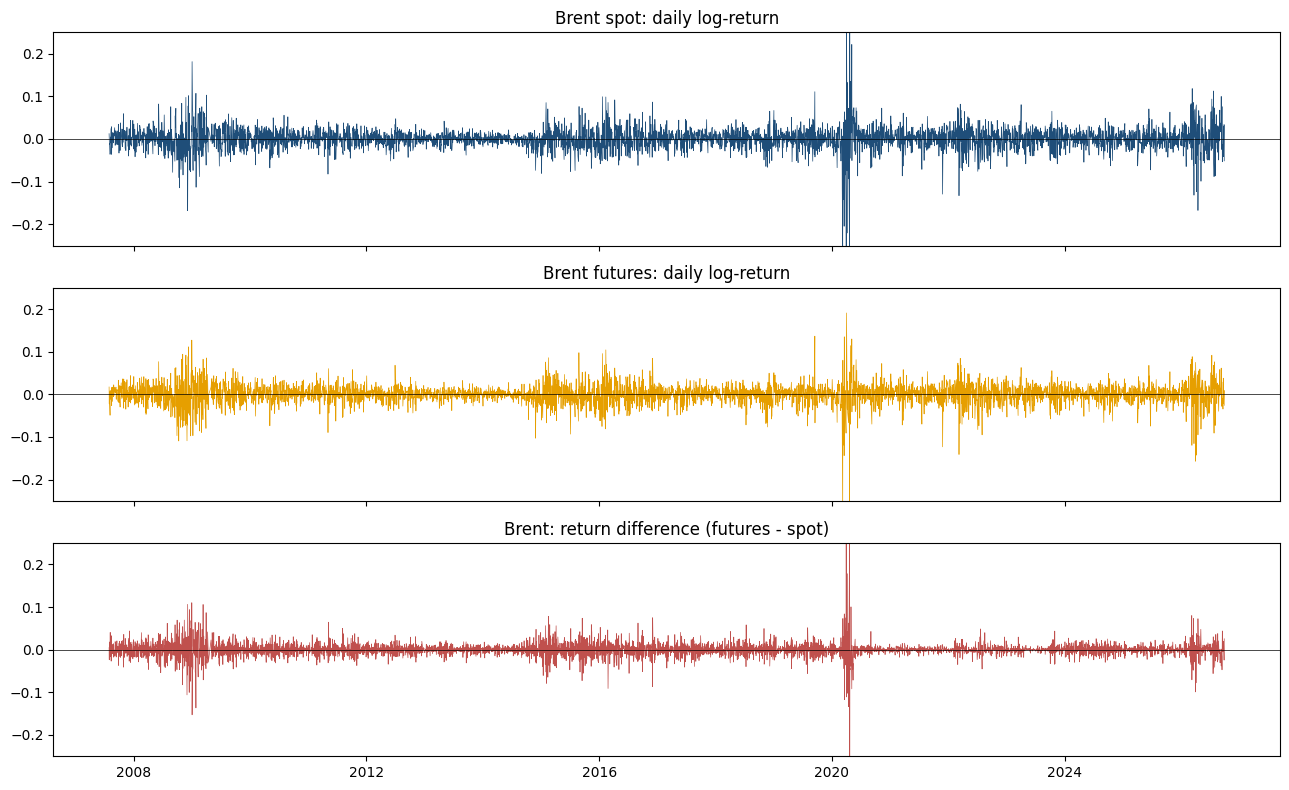

In [5]:
for name, d in data.items():
    fig, ax = plt.subplots(3, 1, figsize=(13, 8), sharex=True)
    ax[0].plot(d.index, d["spot_ret"], color="#1f4e79", lw=0.5); ax[0].set_title(f"{name} spot: daily log-return")
    ax[1].plot(d.index, d["fut_ret"], color="#e69f00", lw=0.5); ax[1].set_title(f"{name} futures: daily log-return")
    ax[2].plot(d.index, d["ret_gap"], color="#c0504d", lw=0.5); ax[2].set_title(f"{name}: return difference (futures - spot)")
    for a in ax: a.set_ylim(-0.25, 0.25); a.axhline(0, color="k", lw=0.5)
    plt.tight_layout(); plt.show()

## 4. Quick numbers

In [6]:
rows = []
for name, d in data.items():
    r = d.dropna()
    rows.append({"pair": name,
                 "return correlation": r["fut_ret"].corr(r["spot_ret"]),
                 "std futures return": r["fut_ret"].std(), "std spot return": r["spot_ret"].std(),
                 "std of difference": r["ret_gap"].std(),
                 "days |diff| > 3%": int((r["ret_gap"].abs() > 0.03).sum()), "total days": len(r)})
display(pd.DataFrame(rows).set_index("pair").round(4))

print("\nLast 10 days with both prices:")
for name, d in data.items():
    print(f"\n{name}"); display(d[["futures", "spot"]].tail(10).assign(**{"spot/fut - 1 (%)": lambda x: (x.spot / x.futures - 1) * 100}).round(2))

,return correlation,std futures return,std spot return,std of difference,days |diff| > 3%,total days
pair,,,,,,
WTI,0.9362,0.0282,0.0299,0.0105,86,6174
Brent,0.7607,0.0243,0.0281,0.0185,280,4723



Last 10 days with both prices:

WTI


,futures,spot,spot/fut - 1 (%)
date,,,
2026-09-16,102.43,103.62,1.16
2026-09-17,101.91,103.21,1.28
2026-09-18,100.30,101.44,1.14
2026-09-21,95.78,96.97,1.24
2026-09-22,94.59,96.41,1.92
2026-09-23,92.16,93.38,1.32
2026-09-24,94.61,95.88,1.34
2026-09-25,92.41,85.23,-7.77
2026-09-28,92.60,99.37,7.31



Brent


,futures,spot,spot/fut - 1 (%)
date,,,
2026-09-16,105.83,127.84,20.80
2026-09-17,104.82,121.18,15.61
2026-09-18,103.87,119.66,15.20
2026-09-21,100.34,116.15,15.76
2026-09-22,99.25,114.89,15.76
2026-09-23,103.08,117.45,13.94
2026-09-24,106.60,120.92,13.43
2026-09-25,104.32,116.01,11.21
2026-09-28,105.28,119.97,13.95
